In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.metrics import structural_similarity, mean_squared_error

## 1. Загрузка изображения в оттенках серого

(400, 600)
uint8


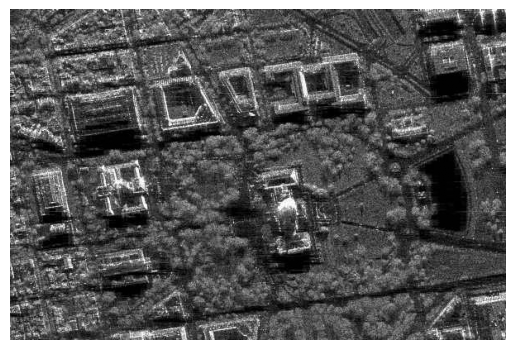

In [2]:
paths = [Path('sar_1_gray.jpg'), Path(r'D:\DownLoads\sar_1_gray.jpg')]
image_path = next(p for p in paths if p.exists())
gray_image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

print(gray_image.shape)
print(gray_image.dtype)
plt.imshow(gray_image, cmap='gray')
plt.axis('off')
plt.show()

## 2. Построение гистограммы

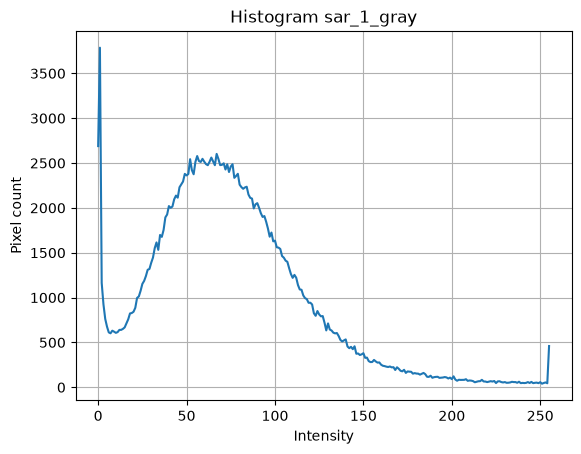

In [3]:
gray_hist = cv2.calcHist([gray_image], [0], None, [256], [0, 256])
plt.plot(gray_hist)
plt.title('Histogram sar_1_gray')
plt.xlabel('Intensity')
plt.ylabel('Pixel count')
plt.grid()
plt.show()

## 3. Гамма-коррекция

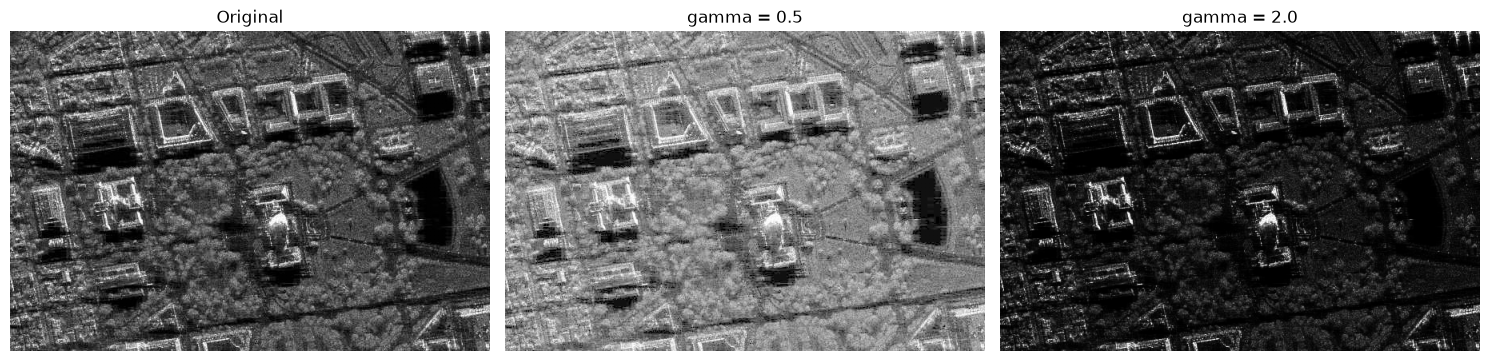

In [4]:
def gamma_filter(image, gamma):
    table = np.round((np.arange(256) / 255.0) ** gamma * 255).astype(np.uint8)
    return cv2.LUT(image, table)

gamma_05 = gamma_filter(gray_image, 0.5)
gamma_2 = gamma_filter(gray_image, 2.0)

images = [gray_image, gamma_05, gamma_2]
titles = ['Original', 'gamma = 0.5', 'gamma = 2.0']

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for i in range(3):
    ax[i].imshow(images[i], cmap='gray', vmin=0, vmax=255)
    ax[i].set_title(titles[i])
    ax[i].axis('off')
plt.tight_layout()
plt.show()

## 4. Сравнение изображений: MSE и SSIM

gamma = 0.5: MSE = 3310.21, SSIM = 0.7854
gamma = 2.0: MSE = 2343.93, SSIM = 0.5352


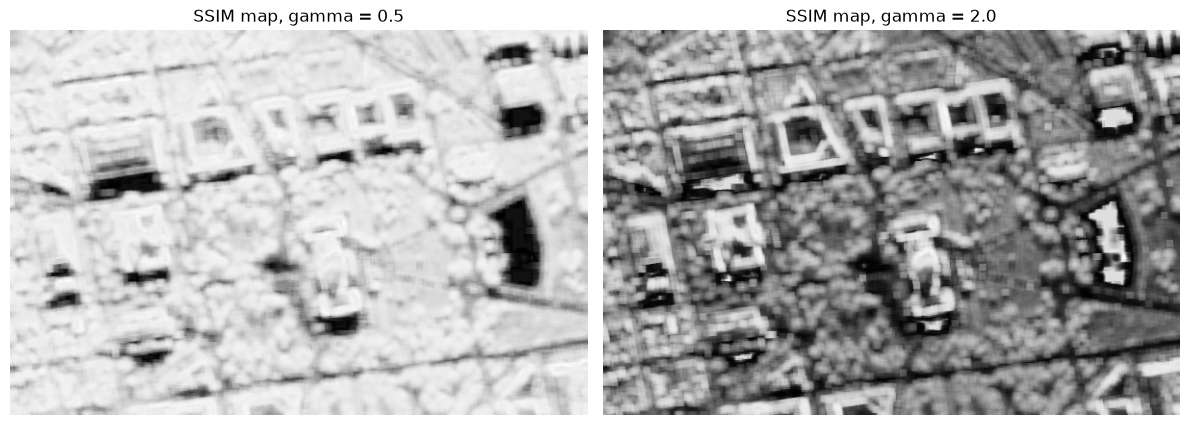

In [5]:
pairs = [('gamma = 0.5', gamma_05), ('gamma = 2.0', gamma_2)]
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

for i, (name, image) in enumerate(pairs):
    mse = mean_squared_error(gray_image, image)
    ssim, diff = structural_similarity(gray_image, image, full=True)
    print(f'{name}: MSE = {mse:.2f}, SSIM = {ssim:.4f}')
    ax[i].imshow(diff, cmap='gray')
    ax[i].set_title('SSIM map, ' + name)
    ax[i].axis('off')
plt.tight_layout()
plt.show()

## 5. Статистическая коррекция по eq_gray

Original: 74.94 43.66
eq_gray: 127.03 74.27
Corrected: 123.12 65.3


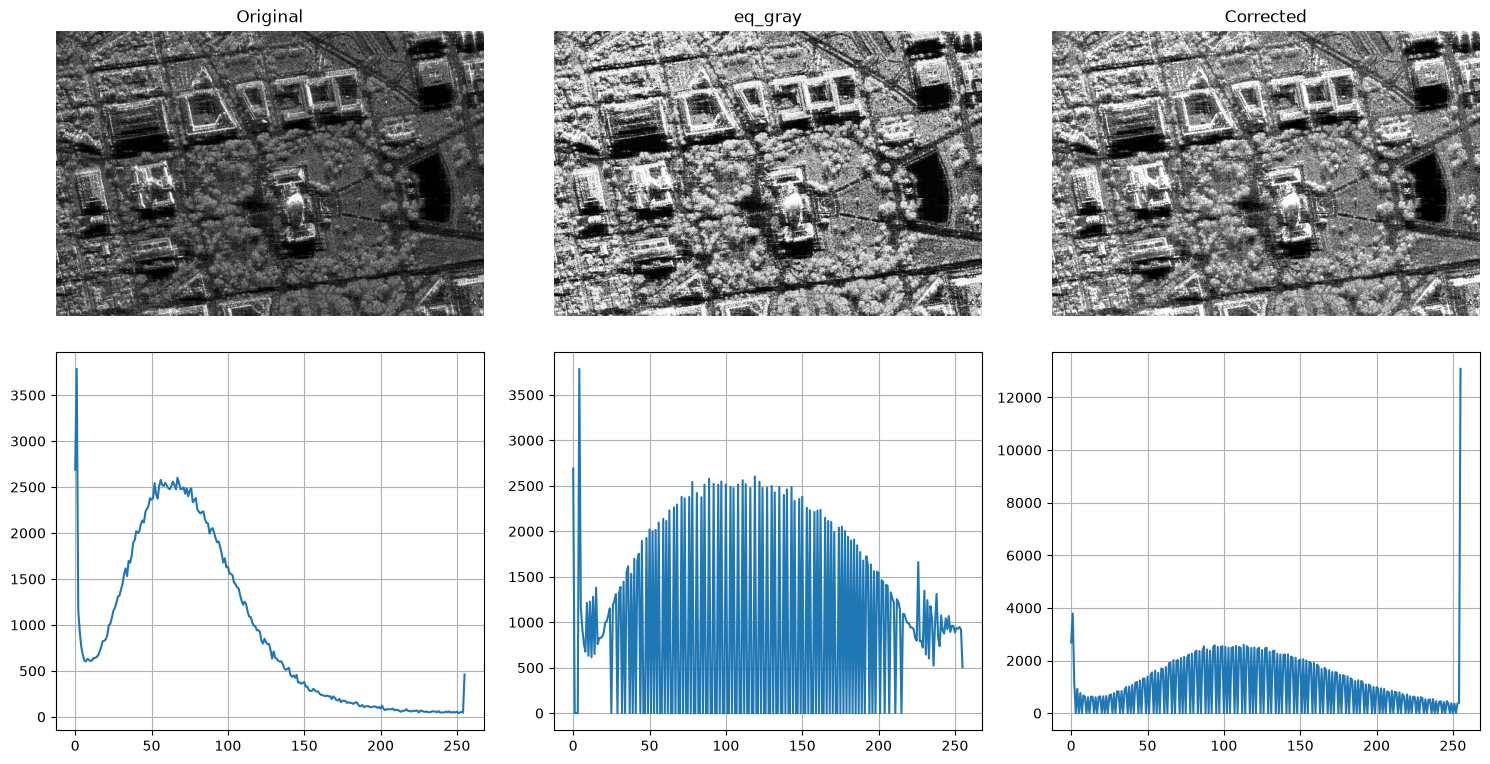

In [6]:
eq_gray = cv2.equalizeHist(gray_image)

mean_s, std_s = eq_gray.mean(), eq_gray.std()
mean_t, std_t = gray_image.mean(), gray_image.std()

corrected = mean_s + (gray_image.astype(float) - mean_t) * std_s / std_t
corrected = np.clip(corrected, 0, 255).astype(np.uint8)

print('Original:', round(mean_t, 2), round(std_t, 2))
print('eq_gray:', round(mean_s, 2), round(std_s, 2))
print('Corrected:', round(corrected.mean(), 2), round(corrected.std(), 2))

images = [gray_image, eq_gray, corrected]
titles = ['Original', 'eq_gray', 'Corrected']

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for i in range(3):
    ax[0, i].imshow(images[i], cmap='gray')
    ax[0, i].set_title(titles[i])
    ax[0, i].axis('off')
    ax[1, i].plot(cv2.calcHist([images[i]], [0], None, [256], [0, 256]))
    ax[1, i].grid()
plt.tight_layout()
plt.show()

## 6. Пороговая фильтрация

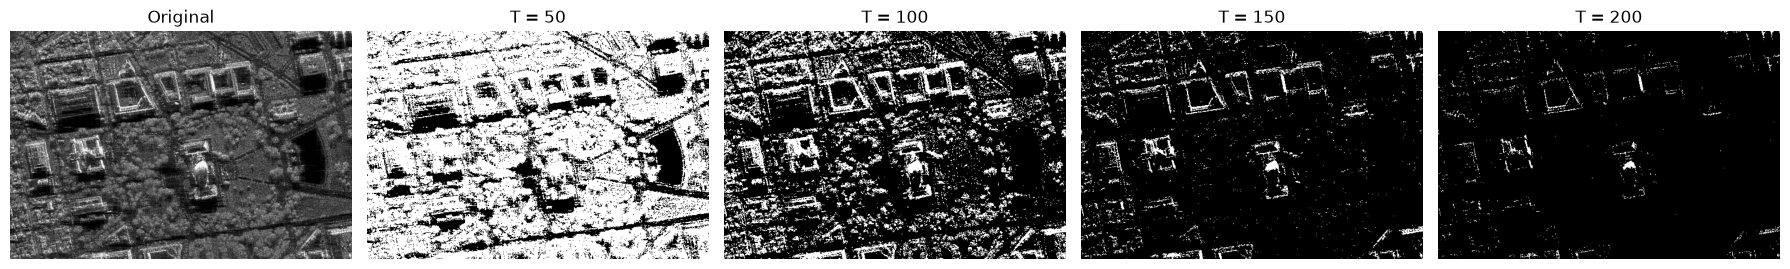

In [7]:
thresholds = [50, 100, 150, 200]
fig, ax = plt.subplots(1, 5, figsize=(18, 4))

ax[0].imshow(gray_image, cmap='gray')
ax[0].set_title('Original')
ax[0].axis('off')

for i, threshold in enumerate(thresholds, 1):
    _, result = cv2.threshold(gray_image, threshold, 255, cv2.THRESH_BINARY)
    ax[i].imshow(result, cmap='gray')
    ax[i].set_title(f'T = {threshold}')
    ax[i].axis('off')
plt.tight_layout()
plt.show()

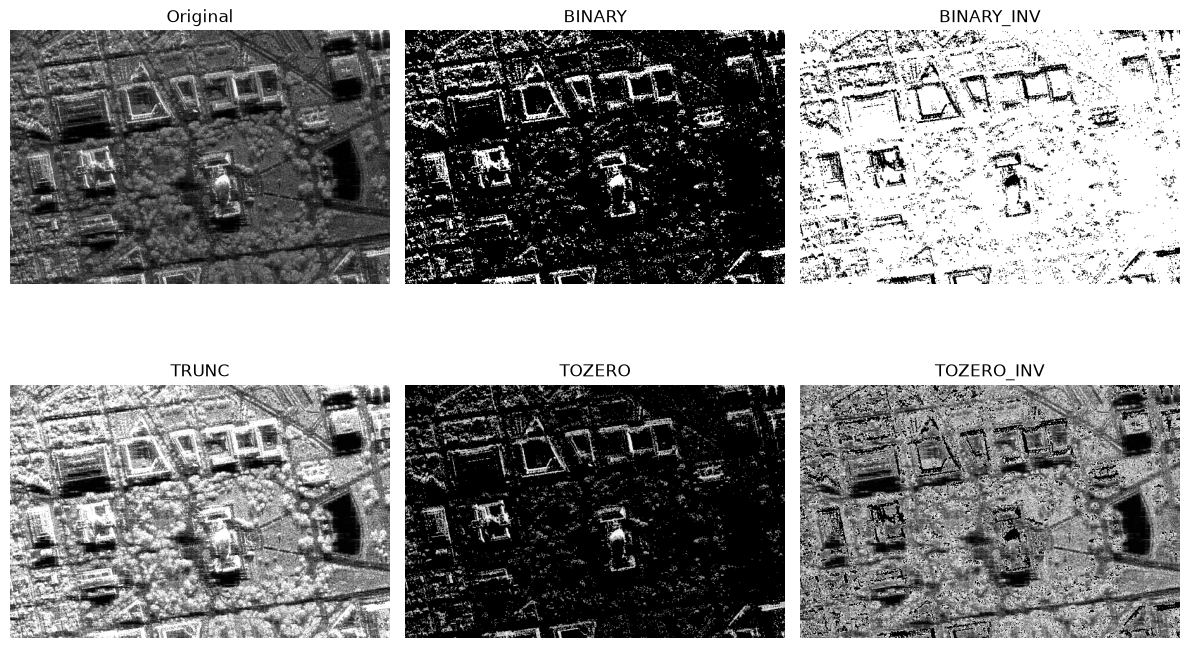

In [8]:
modes = [
    ('BINARY', cv2.THRESH_BINARY),
    ('BINARY_INV', cv2.THRESH_BINARY_INV),
    ('TRUNC', cv2.THRESH_TRUNC),
    ('TOZERO', cv2.THRESH_TOZERO),
    ('TOZERO_INV', cv2.THRESH_TOZERO_INV)
]

fig, ax = plt.subplots(2, 3, figsize=(12, 8))
ax = ax.ravel()
ax[0].imshow(gray_image, cmap='gray')
ax[0].set_title('Original')

for i, (name, mode) in enumerate(modes, 1):
    _, result = cv2.threshold(gray_image, 120, 255, mode)
    ax[i].imshow(result, cmap='gray')
    ax[i].set_title(name)

for item in ax:
    item.axis('off')
plt.tight_layout()
plt.show()

## Вывод

Гамма-коррекция изменила яркость снимка: при gamma = 0.5 изображение стало светлее, при gamma = 2.0 — темнее. Статистическая коррекция изменила контраст по статистике эквализованного изображения. Пороговая фильтрация позволяет выделять светлые и тёмные области при разных значениях порога.